In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import numpy as np
import mpmath

import matplotlib.pylab as plt
from matplotlib.colors import to_rgb
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import seaborn as sns
import scienceplots

plt.style.use('science')

import clusim.clugen as clugen
import clusim.sim as sim
from clusim.clustering import *

def letter_annotation(ax, xoffset, yoffset, letter, size=12, **kwargs):
    
    ax.text(xoffset, yoffset, letter, transform=ax.transAxes, size=size, weight='bold', **kwargs)

In [3]:

def heatmap(data, row_labels, col_labels, ax=None, show_colorbar = False,
            cbar_kw=None, cbarlabel="", **kwargs):
    """
    Create a heatmap from a numpy array and two lists of labels.

    Parameters
    ----------
    data
        A 2D numpy array of shape (M, N).
    row_labels
        A list or array of length M with the labels for the rows.
    col_labels
        A list or array of length N with the labels for the columns.
    ax
        A `matplotlib.axes.Axes` instance to which the heatmap is plotted.  If
        not provided, use current Axes or create a new one.  Optional.
    cbar_kw
        A dictionary with arguments to `matplotlib.Figure.colorbar`.  Optional.
    cbarlabel
        The label for the colorbar.  Optional.
    **kwargs
        All other arguments are forwarded to `imshow`.
    """

    if ax is None:
        ax = plt.gca()

    if cbar_kw is None:
        cbar_kw = {}

    # Plot the heatmap
    im = ax.imshow(data, **kwargs)
    
    if show_colorbar:
        # Create colorbar
        cbar = ax.figure.colorbar(im, ax=ax, **cbar_kw)
        cbar.ax.set_ylabel(cbarlabel, rotation=-90, va="bottom")

    # Show all ticks and label them with the respective list entries.
    ax.set_xticks(range(data.shape[1]), labels=col_labels,
                  rotation=-30, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(data.shape[0]), labels=row_labels)

    # Let the horizontal axes labeling appear on top.
    ax.tick_params(top=True, bottom=False,
                   labeltop=True, labelbottom=False)

    # Turn spines off and create white grid.
    ax.spines[:].set_visible(False)

    ax.set_xticks(np.arange(data.shape[1]+1)-.5, minor=True)
    ax.set_yticks(np.arange(data.shape[0]+1)-.5, minor=True)
    ax.grid(which="minor", color="k", linestyle='-', linewidth=3)
    ax.tick_params(which="minor", bottom=False, left=False)
    if show_colorbar:
        return im, cbar
    else:
        return im


In [5]:
Nsamples = 100
Npoints = 10
NClusterfixed = 2
Nelements = 1000

print(Nelements, NClusterfixed)
ExRange = np.linspace(0.0, 0.5, Npoints)

sample_percent_flip_compare = np.zeros((6, Nsamples, Npoints))


for isample in range(Nsamples):
    #print(isample)
    for iper in range(Npoints):
        
        c1 = clugen.make_equal_clustering(n_elements = Nelements, n_clusters = NClusterfixed)
        c2 = clugen.flip_memberships(c1, num_elements = int(ExRange[iper]*Nelements/NClusterfixed), clu2flip=[0,1])


        c1ent = sim.entropy(np.array(c1.clu_size_seq, dtype=float) / c1.n_elements)
        c2ent = sim.entropy(np.array(c2.clu_size_seq, dtype=float) / c2.n_elements)

        sample_percent_flip_compare[0, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=2, smooth=0, logbase=2, norm_type='sum')
        sample_percent_flip_compare[1, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=3, smooth=0, logbase=2, norm_type='sum')
        sample_percent_flip_compare[2, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=4, smooth=0, logbase=2, norm_type='sum')
        sample_percent_flip_compare[3, isample, iper] = sim.mi(c1, c2)/( 0.5*(c1ent+c2ent))
        sample_percent_flip_compare[4, isample, iper] = sim.rand_index(c1, c2)
        sample_percent_flip_compare[5, isample, iper] = sim.adjrand_index(c1, c2)


1000 2


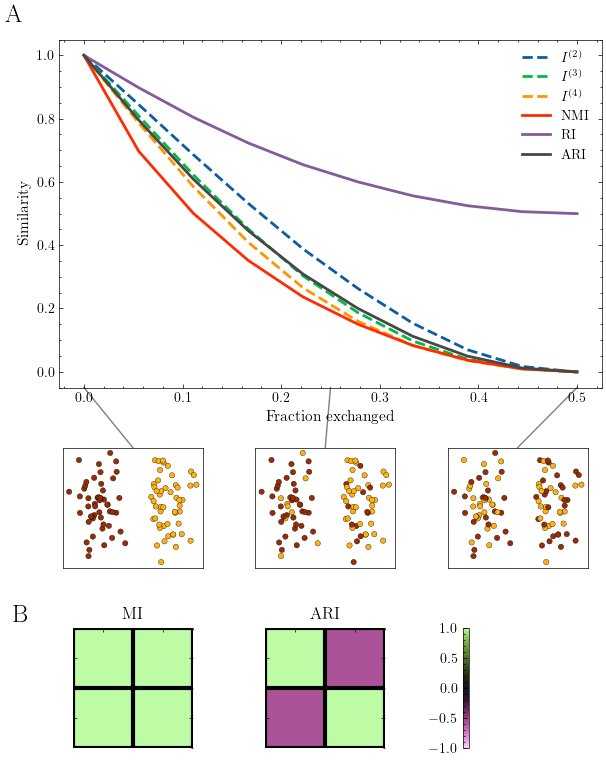

In [8]:


# --------------------------
# Create main plot
# --------------------------
fig, ax_main = plt.subplots(figsize=(7,6))

mlabel = [r"$I^{(2)}$", r"$I^{(3)}$", r"$I^{(4)}$", 'NMI', 'RI', 'ARI']
for imeasure in range(6):
    av = np.mean(sample_percent_flip_compare[imeasure], axis=0)
    ste = 2*np.std(sample_percent_flip_compare[imeasure], axis=0) / np.sqrt(Nsamples)
    ax_main.fill_between(ExRange, av-ste,av+ste,alpha=0.2)

    if imeasure <= 2:
        ls='--'
    else:
        ls = '-'
        
    ax_main.plot(ExRange, av, lw=2, ls=ls, label=mlabel[imeasure])

ax_main.set_ylim(-0.05, 1.05)
ax_main.set_xlabel("Fraction exchanged", fontsize=11)
ax_main.set_ylabel("Similarity", fontsize=11)
ax_main.legend(frameon=False, fontsize=10)


letter_annotation(ax_main, -0.1, 1.05, 'A', size=18, color='k')

# --------------------------
# Inset clustering examples below x-axis
# --------------------------

# create synthetic data
np.random.seed(0)
Nexample = 100
X = np.vstack([
    np.random.normal([0, 0], 0.5, size=(Nexample//2, 2)),
    np.random.normal([3, 0], 0.5, size=(Nexample//2, 2))
])
labels_true = np.array([0]*(Nexample//2) + [1]*(Nexample//2))
base_colors = [to_rgb("#972d07"), to_rgb("#ffb20f")]

epsilons = np.array([0.0, 0.25, 0.5])
x_positions = 2*epsilons   # align with ε
y_inset = -0.2          # relative position below axis

c_base = clugen.partition_from_size_sequence([Nexample//2, Nexample//2] , rand_shuffle=False)


for i,eps in enumerate(epsilons):
    
    # inset axes (below main x-axis)
    ax_inset = fig.add_axes([
        0.13 + x_positions[i]*0.55,   # horizontal placement (adjusted for width)
        0,               # vertical position
        0.2, 0.2          # width, height
    ])
    
    clu = clugen.flip_memberships(c_base, num_elements = int(epsilons[i]*Nexample//2), clu2flip=[0,1])
    colors = [base_colors[e] for e in clu.to_membership_list()]
    
    ax_inset.scatter(X[:,0], X[:,1], c=colors, s=15, edgecolor='k', lw=0.25)
    ax_inset.set_xticks([]); ax_inset.set_yticks([])
    
    
    # connector line from inset to main x-axis
    
    bbox = ax_inset.get_position()
    x_fig = bbox.x0 + bbox.width / 2
    y_fig = bbox.y0 + bbox.height
    
    plot_box = ax_main.get_position()
    axtransform = ax_main.transData + fig.transFigure.inverted()
    figure_coords = axtransform.transform((eps, -0.05))

    line = plt.Line2D(
        [x_fig, figure_coords[0]],
        [y_fig, figure_coords[1] -y_inset -0.01],
        transform=fig.transFigure, alpha=0.5,
        color='k', lw=1.0, clip_on=False
    )
    fig.add_artist(line)
    
N = 1000

c1 = clugen.partition_from_size_sequence([N//2, N//2] , rand_shuffle=False)
c2 = clugen.flip_memberships(c1, num_elements = int(0.25*N//2), clu2flip=[0,1])

mi_resid =sim.mutual_information_residual(c1, c2, highest_order=2)
rand_resid = sim.adjusted_rand_residual(c1, c2, highest_order=2)

mi_resid = mi_resid/mi_resid.max()
rand_resid = rand_resid/rand_resid.max()
norm = Normalize(vmin=-1, vmax=1)

ax_mi = fig.add_axes([
    0.13 + 2*epsilons[0]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
im1 = heatmap(mi_resid, row_labels=[""]*2, col_labels=[""]*2, ax=ax_mi, show_colorbar = False, cmap='vanimo', norm=norm)
ax_mi.set_title("MI", fontsize=12)

ax_rand = fig.add_axes([
    0.13 + 2*epsilons[1]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
im2 = heatmap(rand_resid, row_labels=[""]*2, col_labels=[""]*2, ax=ax_rand, show_colorbar = False, cmap='vanimo', norm=norm)
ax_rand.set_title("ARI", fontsize=12)

ax_cbar = fig.add_axes([
    0.13 + 2*epsilons[2]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
cbar = ax_cbar.figure.colorbar(im1, ax=ax_cbar, location='left')
ax_cbar.axis('off')

letter_annotation(ax_mi, -0.5, 1.05, 'B', size=18, color='k')


# Adjust layout to make space below
plt.subplots_adjust(bottom=0.3)
plt.savefig('unifying_equal_cluster.pdf')
plt.show()


In [9]:
Nsamples = 10
Npoints = 20

Nelements = 1000

PerRange = np.linspace(0.0, 0.5, Npoints)

unequal_shuffle = np.zeros((2, 6, Nsamples, Npoints))
unequal_size_seq = [int(0.8*Nelements), int(0.1*Nelements), int(0.1*Nelements)]

print(unequal_size_seq, sum(unequal_size_seq))


c1 = clugen.partition_from_size_sequence(unequal_size_seq, rand_shuffle=False)
c1ent = sim.entropy(np.array(c1.clu_size_seq, dtype=float) / c1.n_elements)

for isample in range(Nsamples):
    #print(isample)
    for iper in range(Npoints):
        
        
        c2 = clugen.flip_memberships(c1, num_elements = int(PerRange[iper]*unequal_size_seq[1]), clu2flip=[1,2])
        c2ent = sim.entropy(np.array(c2.clu_size_seq, dtype=float) / c2.n_elements)

        unequal_shuffle[0, 0, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=2, smooth=0, logbase=2, norm_type='sum')
        unequal_shuffle[0, 1, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=3, smooth=0, logbase=2, norm_type='sum')
        unequal_shuffle[0, 2, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=4, smooth=0, logbase=2, norm_type='sum')
        unequal_shuffle[0, 3, isample, iper] = sim.mi(c1, c2)/( 0.5*(c1ent+c2ent))
        unequal_shuffle[0, 4, isample, iper] = sim.rand_index(c1, c2)
        unequal_shuffle[0, 5, isample, iper] = sim.adjrand_index(c1, c2)

for isample in range(Nsamples):
    #print(isample)
    for iper in range(Npoints):

        c2 = clugen.flip_memberships(c1, num_elements = int(PerRange[iper]*unequal_size_seq[1]), clu2flip=[0,1])
        c2ent = sim.entropy(np.array(c2.clu_size_seq, dtype=float) / c2.n_elements)

        unequal_shuffle[1, 0, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=2, smooth=0, logbase=2, norm_type='sum')
        unequal_shuffle[1, 1, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=3, smooth=0, logbase=2, norm_type='sum')
        unequal_shuffle[1, 2, isample, iper] = sim.normed_ktuple_approximate_mi(c1, c2, k=4, smooth=0, logbase=2, norm_type='sum')
        unequal_shuffle[1, 3, isample, iper] = sim.mi(c1, c2)/( 0.5*(c1ent+c2ent))
        unequal_shuffle[1, 4, isample, iper] = sim.rand_index(c1, c2)
        unequal_shuffle[1, 5, isample, iper] = sim.adjrand_index(c1, c2)

[800, 100, 100] 1000


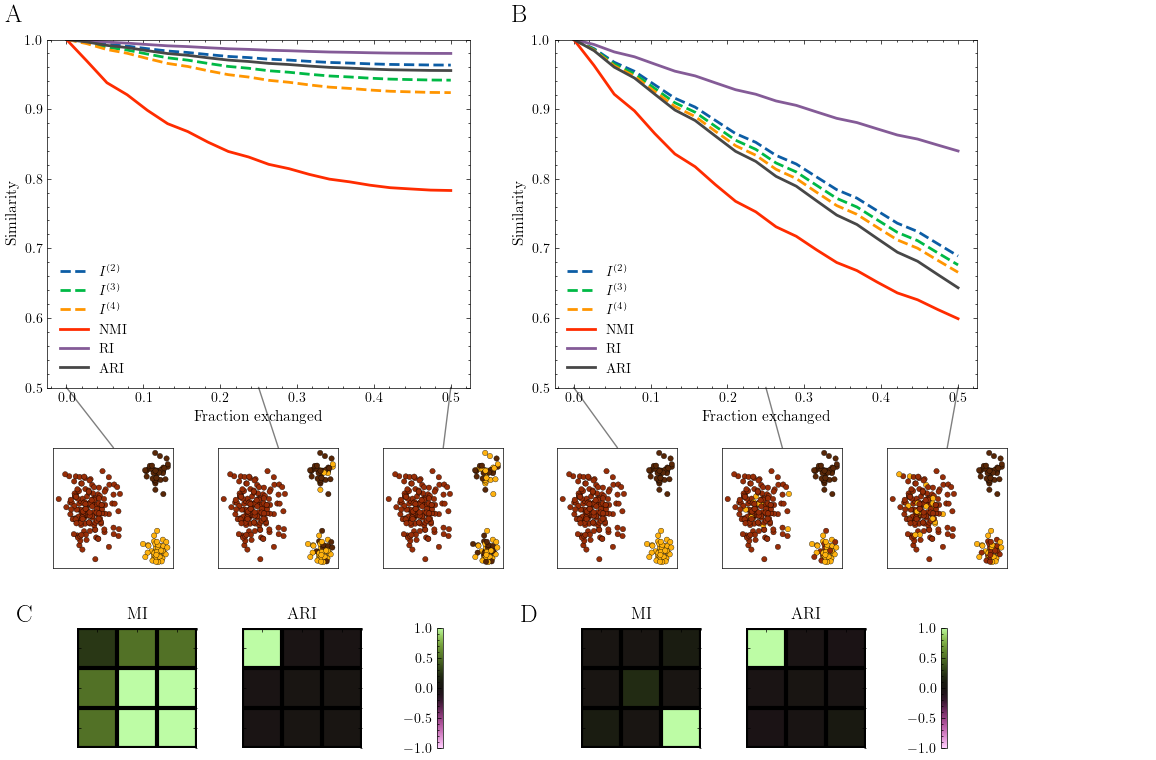

In [13]:
# --------------------------
# Unequal cluster size experiments
# --------------------------

fig, ax = plt.subplots(1,2,figsize=(12,6))
mlabel = [r"$I^{(2)}$", r"$I^{(3)}$", r"$I^{(4)}$", 'NMI', 'RI', 'ARI']

# --------------------------
# 1) small-small exchange
# --------------------------


lax=ax[0]
letter_annotation(lax, -0.1, 1.05, 'A', size=18, color='k')
for imeasure in range(6):
    av = np.mean(unequal_shuffle[0,imeasure], axis=0)
    ste = 2*np.std(unequal_shuffle[0,imeasure], axis=0) / np.sqrt(Nsamples)
    lax.fill_between(PerRange, av-ste,av+ste,alpha=0.2)
    if imeasure <= 2:
        lax.plot(PerRange, av, lw=2, ls='--', label=mlabel[imeasure])
    else:
        lax.plot(PerRange, av, lw=2, label=mlabel[imeasure])

ymin=0.5
lax.set_ylim(ymin, 1.00)
lax.set_xlabel("Fraction exchanged", fontsize=11)
lax.set_ylabel("Similarity", fontsize=11)
lax.legend(frameon=False, fontsize=10)
#ax.set_title("Similarity Measures vs. Noise", fontsize=12)

# example insets

# Synthetic data
np.random.seed(0)
N_big, N_small = 160, 40
N = N_big + N_small

X = np.vstack([
    np.random.normal([0.0, 0.0], 0.55, size=(N_big, 2)),
    np.random.normal([3.0, -1.2], 0.25, size=(N_small, 2)),
    np.random.normal([3.0, 1.2], 0.25, size=(N_small, 2))
])
labels_true = np.array([0]*N_big + [1]*N_small + [2]*N_small)
elm_in_small = sum(labels_true > 0)

base_colors = [to_rgb("#972d07"), to_rgb("#ffb20f"), to_rgb("#582707")]

epsilons = [0.0, 0.25, 0.5]
x_positions = [0,0.25,0.5]   # align with ε
y_inset = -0.2          # relative position below axis



c1 = clugen.partition_from_size_sequence([N_big,N_small,N_small] , rand_shuffle=False)
c2 = clugen.flip_memberships(c1, num_elements = int(0.5*N_small/2), clu2flip=[1,2])
c3 = clugen.flip_memberships(c1, num_elements = int(N_small/2), clu2flip=[1,2])

for eps, clu in zip(epsilons, [c1,c2,c3]):
    # inset axes (below main x-axis)
    ax_inset = fig.add_axes([
        0.13 + eps*0.55,   # horizontal placement (adjusted for width)
        0.2 + y_inset,               # vertical position
        0.1, 0.2          # width, height
    ])
    colors = [base_colors[e] for e in clu.to_membership_list()]
    ax_inset.scatter(X[:,0], X[:,1], c=colors, s=15, edgecolor='k', lw=0.25)
    ax_inset.set_xticks([]); ax_inset.set_yticks([])
    #ax_inset.set_title(f"{xpos}", fontsize=9, pad=2)
    
    bbox = ax_inset.get_position()
    x_fig = bbox.x0 + bbox.width / 2
    y_fig = bbox.y0 + bbox.height
    # connector line from inset to main x-axis
    
    
    axtransform = lax.transData + fig.transFigure.inverted()
    figure_coords = axtransform.transform((eps, ymin))

    line = plt.Line2D(
        [x_fig, figure_coords[0]],
        [y_fig, figure_coords[1] -y_inset -0.01],
        transform=fig.transFigure, alpha=0.5,
        color='k', lw=1.0, clip_on=False
    )
    fig.add_artist(line)

N = 1000

c1 = clugen.partition_from_size_sequence([800,100,100] , rand_shuffle=False)
c2 = clugen.flip_memberships(c1, num_elements = int(100/2), clu2flip=[1,2])

mi_resid =sim.mutual_information_residual(c1, c2, highest_order=2)
rand_resid = sim.adjusted_rand_residual(c1, c2, highest_order=2)
mi_resid = mi_resid/mi_resid.max()
rand_resid = rand_resid/rand_resid.max()
norm = Normalize(vmin=-1, vmax=1)

ax_mi = fig.add_axes([
    0.1 + epsilons[0]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
im1 = heatmap(mi_resid, row_labels=[""]*c1.n_clusters, col_labels=[""]*c2.n_clusters, ax=ax_mi, show_colorbar = False, cmap='vanimo', norm=norm)
ax_mi.set_title("MI", fontsize=12)

ax_rand = fig.add_axes([
    0.1 + epsilons[1]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
im2 = heatmap(rand_resid, row_labels=[""]*c1.n_clusters, col_labels=[""]*c2.n_clusters, ax=ax_rand, show_colorbar = False, cmap='vanimo', norm=norm)
ax_rand.set_title("ARI", fontsize=12)

ax_cbar = fig.add_axes([
    0.15 + epsilons[2]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
cbar = ax_cbar.figure.colorbar(im1, ax=ax_cbar, location='left')
ax_cbar.axis('off')

letter_annotation(ax_mi, -0.5, 1.05, 'C', size=18, color='k')


# --------------------------
# big-small exchange
# --------------------------

lax=ax[1]
letter_annotation(lax, -0.1, 1.05, 'B', size=18, color='k')
for imeasure in range(6):
    av = np.mean(unequal_shuffle[1,imeasure], axis=0)
    ste = 2*np.std(unequal_shuffle[1,imeasure], axis=0) / np.sqrt(Nsamples)
    lax.fill_between(PerRange, av-ste,av+ste,alpha=0.2)
    if imeasure <= 2:
        lax.plot(PerRange, av, lw=2, ls='--', label=mlabel[imeasure])
    else:
        lax.plot(PerRange, av, lw=2, label=mlabel[imeasure])

lax.set_ylim(ymin, 1.00)
lax.set_xlabel("Fraction exchanged", fontsize=11)
lax.set_ylabel("Similarity", fontsize=11)
lax.legend(frameon=False, fontsize=10)
#ax.set_title("Similarity Measures vs. Noise", fontsize=12)

# example insets
epsilons = [0.0, 0.25, 0.5]
y_inset = -0.2          # relative position below axis

c1 = clugen.partition_from_size_sequence([N_big,N_small,N_small] , rand_shuffle=False)
c2 = clugen.flip_memberships(c1, num_elements = int(0.5*N_small/2), clu2flip=[0,1])
c3 = clugen.flip_memberships(c1, num_elements = int(N_small/2), clu2flip=[0,1])

for eps, clu in zip(epsilons, [c1,c2,c3]):
    # inset axes (below main x-axis)
    ax_inset = fig.add_axes([
        0.55 + eps*0.55,   # horizontal placement (adjusted for width)
        0.2 + y_inset,               # vertical position
        0.1, 0.2          # width, height
    ])
    colors = [base_colors[e] for e in clu.to_membership_list()]
    ax_inset.scatter(X[:,0], X[:,1], c=colors, s=15, edgecolor='k', lw=0.25)
    ax_inset.set_xticks([]); ax_inset.set_yticks([])
    #ax_inset.set_title(f"{xpos}", fontsize=9, pad=2)
    
    bbox = ax_inset.get_position()
    x_fig = bbox.x0 + bbox.width / 2
    y_fig = bbox.y0 + bbox.height
    # connector line from inset to main x-axis
    
    
    axtransform = lax.transData + fig.transFigure.inverted()
    figure_coords = axtransform.transform((eps, ymin))

    line = plt.Line2D(
        [x_fig, figure_coords[0]],
        [y_fig, figure_coords[1] -y_inset -0.01],
        transform=fig.transFigure, alpha=0.5,
        color='k', lw=1.0, clip_on=False
    )
    fig.add_artist(line)


N = 1000

c1 = clugen.partition_from_size_sequence([800,100,100] , rand_shuffle=False)
c2 = clugen.flip_memberships(c1, num_elements = int(100/2), clu2flip=[0,1])

mi_resid =sim.mutual_information_residual(c1, c2, highest_order=2)
rand_resid = sim.adjusted_rand_residual(c1, c2, highest_order=2)

mi_resid = mi_resid/mi_resid.max()
rand_resid = rand_resid/rand_resid.max()
norm = Normalize(vmin=-1, vmax=1)

ax_mi = fig.add_axes([
    0.52 + epsilons[0]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
im1 = heatmap(mi_resid, row_labels=[""]*c1.n_clusters, col_labels=[""]*c2.n_clusters, ax=ax_mi, show_colorbar = False, cmap='vanimo', norm=norm)
ax_mi.set_title("MI", fontsize=12)

ax_rand = fig.add_axes([
    0.52 + epsilons[1]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
im2 = heatmap(rand_resid, row_labels=[""]*c1.n_clusters, col_labels=[""]*c2.n_clusters, ax=ax_rand, show_colorbar = False, cmap='vanimo', norm=norm)
ax_rand.set_title("ARI", fontsize=12)

ax_cbar = fig.add_axes([
    0.57 + epsilons[2]*0.55,   # horizontal placement (adjusted for width)
    -0.3 ,               # vertical position
    0.2, 0.2          # width, height
])
cbar = ax_cbar.figure.colorbar(im1, ax=ax_cbar, location='left')
ax_cbar.axis('off')

letter_annotation(ax_mi, -0.5, 1.05, 'D', size=18, color='k')


# Adjust layout to make space below
plt.subplots_adjust(bottom=0.3)
plt.savefig('unifying_unequal_cluster.pdf')
plt.show()
